# 2026/10/20 VJU Intern Lesson2

### We will build a machine learning model to predict solar irradiance, using observational data from the "Himawari" meteorological satellite (for August 2025).



In [ ]:
# Load the libraries to be used
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from tensorflow.keras import Input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
    Concatenate, GlobalAveragePooling2D
)
from tensorflow.keras.optimizers import Adam
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


In [ ]:
# Download Himawari data for August 2025
!git clone https://github.com/ikunao/260909_SS9
!unzip ./260909_SS9/himawari.zip -d /content/


In [ ]:
# Loading Himawari data
path_b03 = '/content/b03_japan/*.jpg'
x1 = []

for p in sorted(glob.glob(path_b03)):
    image = Image.open(p).convert('L')
    x1.append(np.array(image))

x1 = np.array(x1).astype(np.uint8)
print(x1.shape)

In [ ]:
# Checking Himawari data
fig, ax = plt.subplots(figsize=(8,4))
im = ax.imshow(x1[0], cmap='gray', vmin=0, vmax=100)

def update(frame):
    im.set_data(x1[frame])
    return [im]

ani = FuncAnimation(fig, update, frames=48, interval=100)
HTML(ani.to_jshtml())


### [Q] Please display an image of Shikoku from noon on August 25 (Japan Standard Time).


In [ ]:
plt.imshow()

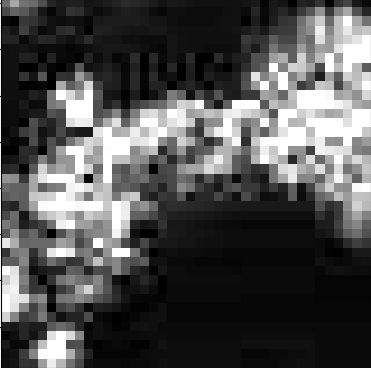

In [ ]:
#Visualization of cloud movement (optical flow method)

img1 = x1[0].astype(np.uint8)
img2 = x1[5].astype(np.uint8)

dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_FAST)
flow = dis.calc(img1, img2, None)

mask = img1 > 10
ys, xs = np.where(mask)
idx = np.random.choice(len(xs), 500, replace=False)

plt.figure(figsize=(12, 6))
plt.imshow(img2, cmap='gray', vmin=0, vmax=100)
cmap = plt.get_cmap("jet")

for x, y in zip(xs[idx], ys[idx]):
    dx, dy = flow[y, x]
    color = cmap((dx*dx + dy*dy)*0.002)
    plt.arrow(
        x, y, dx, dy, color=color, linewidth=2, head_width=2
    )


In [ ]:
# Load weather data for Kochi.

df = pd.read_csv(
    '/content/kisho_kochi.csv',
    encoding='shift_jis',
    parse_dates=['年月日時'],
    index_col='年月日時'
)

print(df[:20])

In [ ]:
# Correlation between clear-sky solar irradiance and actual solar irradiance.

R2 = r2_score(df["日射量"], df["晴天時日射量"])  #solar radiation, solar radiation on sunny day

plt.scatter(df["晴天時日射量"], df["日射量"],label=f'R²={R2:.3f}')
plt.xlabel('cloudless')
plt.ylabel('Actual')
plt.legend()
plt.show()


### [] 問題　以下の学習コードを適宜変更し、最も精度がよくなった（R2が大きい）場合の条件とR2の値を報告してください。

In [ ]:
#Creation of training data

#Explanatory variables (satellite imagery)
X_img = np.array(x1).astype(np.uint8)
X_img = (X_img - np.mean(X_img)) / (np.max(X_img) - np.min(X_img))

X_img = X_img[0:360]                #Extract the first 360 items (representing 24 × 15 days).
X_img = X_img[:,::5, ::10]          #Downscale by subsampling pixels (from 400x200 to 40x40).

#Explanatory variable (scalar)
x11 = np.array(df["晴天時日射量"], dtype=np.float32)  #solar radiation on sunny day
x12 = np.array(df["気温"], dtype=np.float32)  #Temperature
x13 = np.array(df["相対湿度"], dtype=np.float32)  #Humidity
x14 = np.array(df["降水量"], dtype=np.float32)  #precipitation
x15 = np.array(df["現地気圧"], dtype=np.float32)  #Atmospheric pressure

X_scalar = np.stack([x11, x12], axis=1)
X_scalar = X_scalar[0:360]
mean = np.nanmean(X_scalar, axis=0)
minv = np.nanmin(X_scalar, axis=0)
maxv = np.nanmax(X_scalar, axis=0)
X_scalar = (X_scalar - mean) / (maxv - minv)

#Target variable
y = np.array(df["日射量"], dtype=np.float32)  #solar radiation
y = y[0:360]

# Split into training and validation data (first 66% → train, remaining 33% → val)
split_idx = int(len(X_img) * 0.66)
X_img_train, X_img_val = X_img[:split_idx], X_img[split_idx:]
X_scalar_train, X_scalar_val = X_scalar[:split_idx], X_scalar[split_idx:]
y_train, y_val = y[:split_idx], y[split_idx:]

In [ ]:
# Lightweight CNN Regression Network Integrating Image Features and Numerical Information

# Image convolution
image_input = Input(shape=(40, 40, 1))
v = Conv2D(8, (3, 3), activation='relu', padding='same', dilation_rate=3)(image_input)
v = MaxPooling2D((2, 2))(v)
v = Conv2D(8, (3, 3), activation='relu', padding='same', dilation_rate=3)(v)
v = GlobalAveragePooling2D()(v)
v = Dense(8, activation='relu')(v)

# NN for numerical data
meta_input = Input(shape=(2,))
m = Dense(8, activation='relu')(meta_input)
m = Dense(8, activation='relu')(m)

# Combine images and numerical values
combined = Concatenate()([v, m])
output = Dense(1, activation='linear')(combined)

# Model building
model = Model(inputs=[image_input, meta_input], outputs=output)
model.compile(optimizer=Adam(learning_rate=1e-3), loss='mse')


In [ ]:
# Learning
history = model.fit(
    [X_img_train, X_scalar_train], y_train,
    validation_data=([X_img_val, X_scalar_val], y_val),
    epochs=10,
    batch_size=8
)

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.show()

In [ ]:
# Prediction results
y_pred = model.predict([X_img_val, X_scalar_val]).flatten()

reg_model = LinearRegression()
reg_model.fit(y_val.reshape(-1, 1), y_pred)
reg_line = reg_model.predict(y_val.reshape(-1, 1))
R2 = np.corrcoef(y_val, y_pred)[0, 1]

plt.scatter(x=y_val, y=y_pred, color='blue', label='Predicted vs True')
plt.plot(y_val, reg_line, color='red', label=f'Regression Line (R={R2:.3f})')
plt.xlabel('True PPFD')
plt.ylabel('Predicted PPFD')
plt.legend()
plt.show()

In [ ]:
# Display of time-series results (the latter portion not used for training)
y_pred = model.predict([X_img_val ,X_scalar_val]).flatten()
time_index = np.arange(len(y_val))

plt.figure(figsize=(10, 4))
plt.plot(time_index, y_val, label='True', color='blue', linewidth=2)
plt.plot(time_index, y_pred, label='Predicted', color='orange', linewidth=2)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()